# Credit Card Default: Repayment Delays by Demographic Group

This notebook looks at how often clients **delay their credit card repayments**, whether delay behaviour differs by **gender, education and marital status**, and how delay frequency relates to the chance of **defaulting the next month**.

**Dataset:** [UCI Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients) (ID 350): 30,000 credit card clients in Taiwan, with six months of history from April to September 2005 and no missing values.

| Column | Meaning |
|---|---|
| `X1` | Credit limit (NT dollars) |
| `X2` | Gender (1 = male, 2 = female) |
| `X3` | Education (1 = graduate school, 2 = university, 3 = high school, 4 = other) |
| `X4` | Marital status (1 = married, 2 = single, 3 = other) |
| `X5` | Age (years) |
| `X6`–`X11` | Repayment status, September → April (-1 = paid on time, 1–9 = months of delay) |
| `X12`–`X17` | Bill statement amount, September → April |
| `X18`–`X23` | Amount paid, September → April |
| `Y` | **Target:** default payment next month (1 = yes, 0 = no) |

## 1. Load the data and label the demographic groups

- `fetch_ucirepo(id=350)` downloads the dataset. `X` holds the 23 features and `y` holds the target column `Y`.
- The metadata and variable table are printed to show what each column means. The `description` column gives the original names (`LIMIT_BAL`, `PAY_0`, `BILL_AMT1`, ...).
- `X` and `y` are joined into one DataFrame `df`. All EDA work happens on the copy `eda`, so the original data stays unchanged.
- The numeric codes for gender, education and marital status are mapped to readable labels. The data also contains codes that the documentation doesn't list (education 0, 5 and 6, and marriage 0). `.fillna("Unknown")` groups these under **Unknown**.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
default_of_credit_card_clients = fetch_ucirepo(id=350) 
  
# data (as pandas dataframes) 
X = default_of_credit_card_clients.data.features 
y = default_of_credit_card_clients.data.targets 
  
# metadata 
print(default_of_credit_card_clients.metadata) 
  
# variable information 
print(default_of_credit_card_clients.variables) 

df = pd.concat([X, y], axis=1)
eda = df.copy()

# Convert demographics into meaningful categories
eda["Gender"] = eda["X2"].map({
    1: "Male",
    2: "Female"
}).fillna("Unknown")

eda["Education"] = eda["X3"].map({
    1: "Graduate School",
    2: "University",
    3: "High School",
    4: "Other"
}).fillna("Unknown")

eda["Marriage"] = eda["X4"].map({
    1: "Married",
    2: "Single",
    3: "Other"
}).fillna("Unknown")

{'uci_id': 350, 'name': 'Default of Credit Card Clients', 'repository_url': 'https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients', 'data_url': 'https://archive.ics.uci.edu/static/public/350/data.csv', 'abstract': "This research aimed at the case of customers' default payments in Taiwan and compares the predictive accuracy of probability of default among six data mining methods.", 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 30000, 'num_features': 23, 'feature_types': ['Integer', 'Real'], 'demographics': ['Sex', 'Education Level', 'Marital Status', 'Age'], 'target_col': ['Y'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Fri Mar 29 2024', 'dataset_doi': '10.24432/C55S3H', 'creators': ['I-Cheng Yeh'], 'intro_paper': {'ID': 365, 'type': 'NATIVE', 'title': 'The comparisons of data mining techniques for the predictive accuracy of 

## 2. Create repayment-delay features

`X6`–`X11` store the repayment status for each of the six months. A **positive value** is the number of months the payment was late. A value of **0 or below** (-2, -1, 0) means no delay was recorded for that month.

Three new features summarise each client's six-month history:

| Feature | How it is calculated | Meaning |
|---|---|---|
| `Delayed_Months` | Number of months with status > 0 | How many of the 6 months the client paid late (0–6) |
| `Max_Delay` | Highest status after negative values are set to 0 | The worst delay seen, in months (0 = never late) |
| `Ever_Delayed` | `Delayed_Months > 0` | `True` if the client paid late at least once |

In [7]:
pay_cols = ["X6", "X7", "X8", "X9", "X10", "X11"]

# Count months with positive repayment-delay status
eda["Delayed_Months"] = (eda[pay_cols] > 0).sum(axis=1)

# Maximum recorded positive delay status
eda["Max_Delay"] = eda[pay_cols].clip(lower=0).max(axis=1)

# Whether the customer has any recorded delay
eda["Ever_Delayed"] = eda["Delayed_Months"] > 0

## 3. Delay behaviour by demographic group

`demographic_summary()` groups the clients by one demographic column and calculates:

- **Total_Clients**: number of clients in the group
- **Avg_Delayed_Months**: average number of late months, out of 6
- **Ever_Delayed_Rate**: percentage of clients who were late at least once (mean of the `True`/`False` column × 100)
- **Avg_Max_Delay**: average of each client's worst delay

The function is run for gender, education and marital status.

In [8]:
def demographic_summary(data, group_col):
    summary = data.groupby(group_col).agg(
        Total_Clients=("Delayed_Months", "size"),
        Avg_Delayed_Months=("Delayed_Months", "mean"),
        Ever_Delayed_Rate=("Ever_Delayed", "mean"),
        Avg_Max_Delay=("Max_Delay", "mean")
    )

    summary["Ever_Delayed_Rate"] *= 100
    return summary.round(2)

print(demographic_summary(eda, "Gender"))
print(demographic_summary(eda, "Education"))
print(demographic_summary(eda, "Marriage"))

        Total_Clients  Avg_Delayed_Months  Ever_Delayed_Rate  Avg_Max_Delay
Gender                                                                     
Female          18112                0.78              32.50           0.64
Male            11888                0.92              35.18           0.74
                 Total_Clients  Avg_Delayed_Months  Ever_Delayed_Rate  \
Education                                                               
Graduate School          10585                0.67              30.51   
High School               4917                0.99              37.95   
Other                      123                0.19              16.26   
University               14030                0.93              34.90   
Unknown                    345                0.25              16.23   

                 Avg_Max_Delay  
Education                       
Graduate School           0.57  
High School               0.81  
Other                     0.24  
University         

### Findings

**Gender**
- Women make up about 60% of the dataset (18,112 vs 11,888).
- Men are a little more likely to pay late: **35.2%** were delayed at least once, against **32.5%** of women. Men also have more late months on average (0.92 vs 0.78).

**Education**
- **High school** clients have the most delays: 37.95% were ever late, with the highest average late months (0.99) and worst average delay (0.81).
- **University** clients come next (34.90%). **Graduate school** clients have the fewest delays of the three main groups (30.51%).
- **Other** and **Unknown** show much lower rates (about 16%). Both groups are very small (123 and 345 clients), so these numbers are less reliable.

**Marital status**
- Married and single clients are almost the same (about 33.5% ever late, 0.68 average worst delay).
- **Other** is slightly higher (36.84%), but it has only 323 clients. **Unknown** has only 54.

**In short:** education shows the clearest difference in delay behaviour. Gender shows a small gap, and marital status makes little difference.

## 4. How many months each education group was late

- `pd.crosstab(..., normalize="index")` counts clients for each education level and number of delayed months, then turns each row into percentages. **Each row adds up to 100%**, so groups of very different sizes can be compared fairly.
- The heatmap shows these percentages. Darker cells mean a larger share of that education group.

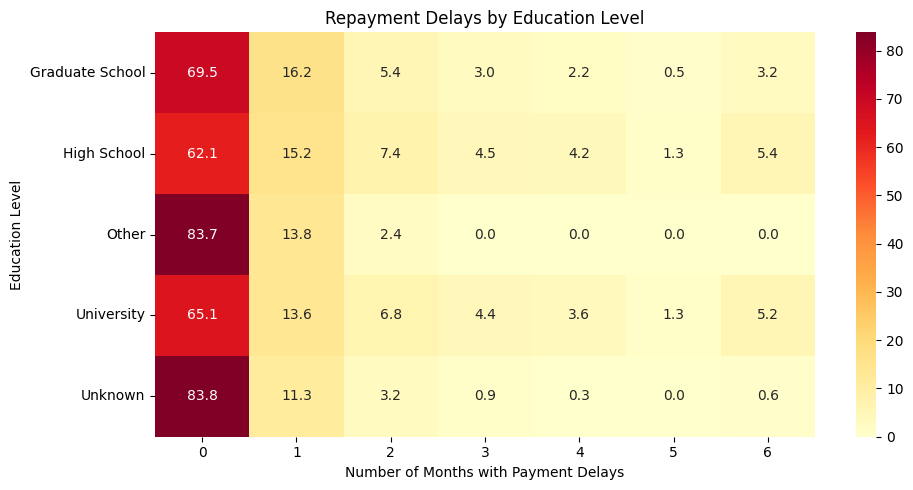

In [9]:
delay_distribution = pd.crosstab(
    eda["Education"],
    eda["Delayed_Months"],
    normalize="index"
) * 100

plt.figure(figsize=(10, 5))

sns.heatmap(
    delay_distribution,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title("Repayment Delays by Education Level")
plt.xlabel("Number of Months with Payment Delays")
plt.ylabel("Education Level")
plt.tight_layout()
plt.show()

### Findings

- Most clients in every group **never paid late** (the 0 column): 69.5% of graduate school, 65.1% of university and 62.1% of high school clients.
- High school and university clients have more **repeated delays**. About **5.4%** and **5.2%** of them were late in all 6 months, against 3.2% of graduate school clients.
- In the Other and Unknown groups, about 84% never paid late and almost nobody was late for more than 2 months. This matches section 3, but both groups are small.

## 5. Default risk by number of late months and education

- Clients are grouped by `Education` and `Delayed_Months`. Because `Y` is 0/1, the **mean of `Y` is the default rate** for each group, and `size` is the number of clients.
- `observed=True` keeps only combinations that actually appear in the data.
- `Default_Rate` is multiplied by 100 to show it as a percentage.
- The chart only shows the three main education levels. **Other** and **Unknown** are too small to give reliable default rates.
- The line chart shows how the next-month default rate changes as the number of late months goes up, with one line per education level.

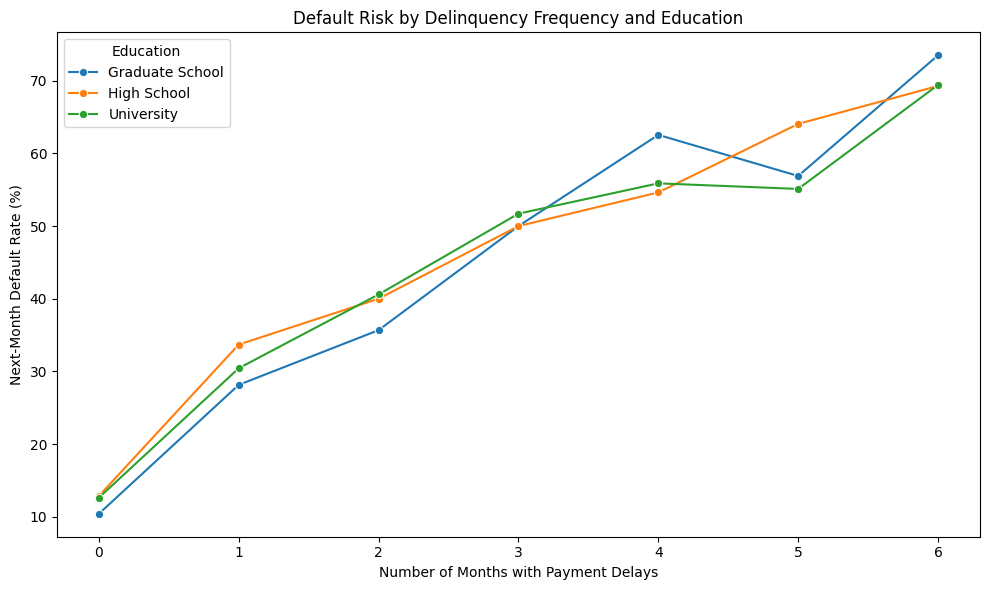

In [10]:
# Calculate default rate by education and delayed months
risk = (
    eda.groupby(
        ["Education", "Delayed_Months"],
        observed=True
    )["Y"]
    .agg(
        Default_Rate="mean",
        Total_Clients="size"
    )
    .reset_index()
)

risk["Default_Rate"] *= 100

# Focus on the three main education categories
main_education = [
    "Graduate School",
    "University",
    "High School"
]

risk = risk[risk["Education"].isin(main_education)]

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=risk,
    x="Delayed_Months",
    y="Default_Rate",
    hue="Education",
    marker="o"
)

plt.title("Default Risk by Delinquency Frequency and Education")
plt.xlabel("Number of Months with Payment Delays")
plt.ylabel("Next-Month Default Rate (%)")
plt.tight_layout()
plt.show()

### Findings

- **More late months means a much higher default rate.** It rises from about **10–13%** for clients who were never late to about **70–74%** for clients who were late in all 6 months.
- The biggest jump is from **0 to 1** late month (about 10–13% to 28–34%). Being late **even once** makes default roughly 2.5 times more likely.
- The three education lines stay close together. Once we know how often a client paid late, education adds little extra information. Graduate school clients are slightly lower-risk at 0–2 late months.
- The up-and-down shape of the graduate school line at 4–5 months is probably **noise from small groups**. Only about 2.2% and 0.5% of graduate school clients (roughly 230 and 50 people) fall in those groups.

## 6. Default risk by number of late months and gender

This is the same analysis as section 5, grouped by gender instead of education.

- `.agg(["mean", "size"])` creates a `mean` column (default rate between 0 and 1) and a `size` column (number of clients).
- `Default_Rate` is `mean × 100`, so it is shown as a percentage.
- The code comment assumes `Y = 1` means default. The dataset documentation confirms this (default payment: Yes = 1, No = 0).

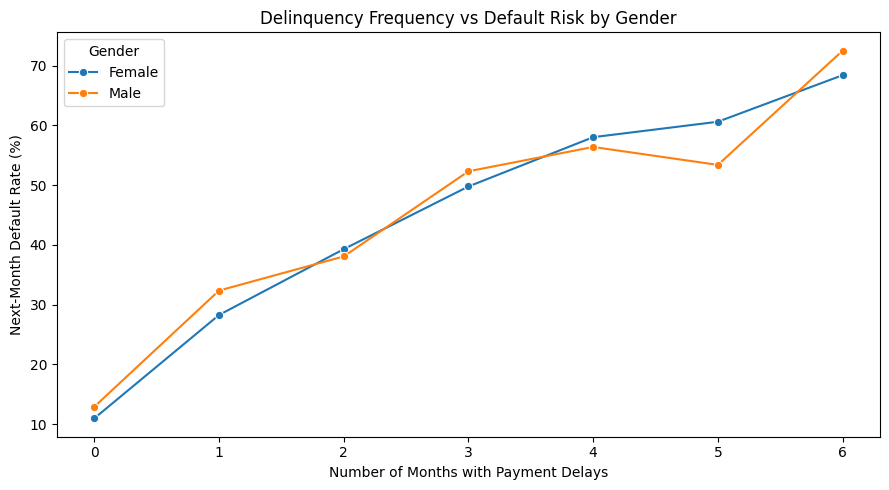

In [11]:
# Assumes Y = 1 for default, 0 otherwise
risk_by_gender = (
    eda.groupby(["Gender", "Delayed_Months"])["Y"]
       .agg(["mean", "size"])
       .reset_index()
)

risk_by_gender["Default_Rate"] = risk_by_gender["mean"] * 100

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=risk_by_gender,
    x="Delayed_Months",
    y="Default_Rate",
    hue="Gender",
    marker="o"
)

plt.title("Delinquency Frequency vs Default Risk by Gender")
plt.xlabel("Number of Months with Payment Delays")
plt.ylabel("Next-Month Default Rate (%)")
plt.tight_layout()
plt.show()

### Findings

- Both genders show the **same strong upward trend**. The default rate goes from about 11–13% with no late months to about 68–72% with 6 late months.
- With **0–1 late months**, men default a little more often than women (about 13% vs 11%, and 32% vs 28%).
- From 2 late months onward, the two lines cross several times, so there is **no consistent gender gap**. The dip for men at 5 months is probably small-sample noise.
- Compared with repayment history, **gender has only a small effect** on default risk.

## Summary

1. **Repayment history matters most.** The number of late months strongly predicts next-month default, whatever the client's gender or education. The default rate rises from about 11% with no late months to about 70% with 6 late months.
2. **Demographic differences are small.** High school and university clients pay late more often than graduate school clients, and men slightly more often than women. Marital status makes almost no difference.
3. **For modelling:** the new features `Delayed_Months`, `Max_Delay` and `Ever_Delayed` look like strong predictors. Demographic columns will probably add little on top of them. The small **Other** and **Unknown** groups may need to be merged or handled with care.